# Phase 8: PCE Surrogate and Sobol' Sensitivity (analysis A)

**Question:** across the league, what makes one game's prediction different from another's?
Team offense, team defense, the starting goalies, or the league-wide terms (scoring level, home ice,
tie inflation, OT factor)?

The "truth model" is the exact game model (`game_model.outcome_probs`). `build_pce.py` fits a PCE to it
and reads the Sobol' indices off the coefficients (the soil project's method); a Saltelli Monte Carlo
estimate on the exact model checks them.

Run first (after the rebuild order `fit_hierarchical` → `late_game`):
`py -m src.pipelines.build_pce`

**Sections**
1. Setup
2. Known-answer test: Ishigami function
3. The inputs and their ranges
4. Truth-model checks
5. Choosing the polynomial degree
6. Surrogate accuracy (saved PCE)
7. Sobol' indices, PCE vs Monte Carlo *(the main result)*
8. Grouped: team ratings vs goalies vs league terms
9. What the indices mean in probability units (main-effect curves)
10. Robustness: does the range choice change the answer?
11. Summary

$S_i$ = share of the output variance from input $i$ alone; $S_{T,i}$ = share including its interactions.
$S_{T,i} - S_i$ small means input $i$ acts mostly on its own.

## 1. Setup

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import sys; sys.path.insert(0, "..")
import json, pickle, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config.settings import OUTPUT_DIR
from src.data.db import get_connection
from src.processing.late_game import load_params
from src.models.active_fit import read_active, active_fit_path, window_games
from src.models.game_model import load_track_b, outcome_probs
from src.models.stochastic import pce
from src.analysis.sensitivity import (INPUT_NAMES, GROUPS, QOI_LABELS, input_specs, game_qoi,
                                      truth_predictor, sd_contributions)

def check(label, ok, note=""):
    print(f"{'PASS ' if ok else 'CHECK'}  {label}" + (f"   ({note})" if note else ""))

info = read_active()
fit_path = active_fit_path()
draws, teams = load_track_b(fit_path)
late = load_params(OUTPUT_DIR / "models" / "late_game.json")
conn = get_connection()
gt, _ = window_games(conn, info)
conn.close()
specs, spec_info = input_specs(draws, gt, late)
STEM = OUTPUT_DIR / "models" / f"pce_{fit_path.stem}"
print(f"Active fit {fit_path.name}: {len(gt):,} games, {info['start']} to {info['end']}")
print(f"Saved PCE: {STEM.name}.pkl " + ("found" if STEM.with_suffix('.pkl').exists() else "MISSING: run py -m src.pipelines.build_pce"))

Active fit trackbxg_w365_20261025.nc: 1,355 games, 2025-10-25 to 2026-10-25
Saved PCE: pce_trackbxg_w365_20261025.pkl found


## 2. Known-answer test: Ishigami function

$f = \sin x_1 + 7 \sin^2 x_2 + 0.1\, x_3^4 \sin x_1$ on $[-\pi, \pi]^3$ is the standard Sobol' test:
its indices are known exactly, $x_3$ matters only through its interaction with $x_1$ ($S_3 = 0$, $S_{T,3} = 0.24$),
and it needs a high degree. Both the PCE and Saltelli must recover the exact values.

In [2]:
S_ex, ST_ex, V_ex = pce.ishigami_exact()
P_ish = 10
n_terms = len(pce.total_order_indices(3, P_ish))
r = pce.build_pce_surrogate(pce.ishigami, pce.ISHIGAMI_SPECS, P=P_ish, N_train=3 * n_terms, N_test=2000,
                            vectorized=True, verbose=False)
s = r["surrogates"]["ishigami"]
f = lambda X: pce.ishigami(pce.xi_to_theta(X, pce.ISHIGAMI_SPECS))["ishigami"]
S_sal, ST_sal, V_sal = pce.saltelli_sobol(f, 3, N=2**15, seed=0)
print(pd.DataFrame({"S exact": S_ex, "S PCE": s["S"], "S Saltelli": S_sal,
                    "S_T exact": ST_ex, "S_T PCE": s["S_T"], "S_T Saltelli": ST_sal},
                   index=["x1", "x2", "x3"]).round(4).to_string())
print(f"variance: exact {V_ex:.4f}, PCE {s['variance']:.4f}, Saltelli {V_sal:.4f}; PCE hold-out R2 {s['R2_holdout']:.5f}")
check("PCE matches the exact indices (within 0.005)",
      np.abs(np.r_[s["S"] - S_ex, s["S_T"] - ST_ex]).max() < 0.005)
check("Saltelli matches the exact indices (within 0.01)",
      np.abs(np.r_[S_sal - S_ex, ST_sal - ST_ex]).max() < 0.01)

    S exact   S PCE  S Saltelli  S_T exact  S_T PCE  S_T Saltelli
x1   0.3139  0.3140      0.3141     0.5576   0.5577        0.5576
x2   0.4424  0.4423      0.4421     0.4424   0.4423        0.4424
x3   0.0000  0.0000      0.0000     0.2437   0.2437        0.2437
variance: exact 13.8446, PCE 13.8384, Saltelli 13.8447; PCE hold-out R2 0.99999
PASS   PCE matches the exact indices (within 0.005)
PASS   Saltelli matches the exact indices (within 0.01)


## 3. The inputs and their ranges

Each input is uniform with the **same mean and standard deviation as its real distribution**
(range = mean ± √3 sd). Sobol' indices measure shares of variance, so what matters is how much each input
really varies. Team inputs vary across the 32 teams; goalie inputs across the starters in the fit window;
league terms (the same in every game) over their posterior uncertainty.

      input    mean     sd     low   high                                                  source
   off_home -0.0003 0.0699 -0.1213 0.1208      sd of the teams' offense ratings (posterior means)
   def_home -0.0005 0.0686 -0.1193 0.1182      sd of the teams' defense ratings (posterior means)
   off_away -0.0003 0.0699 -0.1213 0.1208                                                    same
   def_away -0.0005 0.0686 -0.1193 0.1182                                                    same
goalie_home  0.0048 0.0153 -0.0218 0.0314 sd of the starting goalies' offsets over the fit window
goalie_away  0.0048 0.0153 -0.0218 0.0314                                                    same
     alpha0  1.0179 0.0269  0.9712 1.0646                                   posterior mean and sd
 alpha_home  0.0543 0.0246  0.0117 0.0968                                   posterior mean and sd
        rho  0.7213 0.1070  0.5360 0.9066                                   posterior mean and sd
  ot_factor  2.0907 

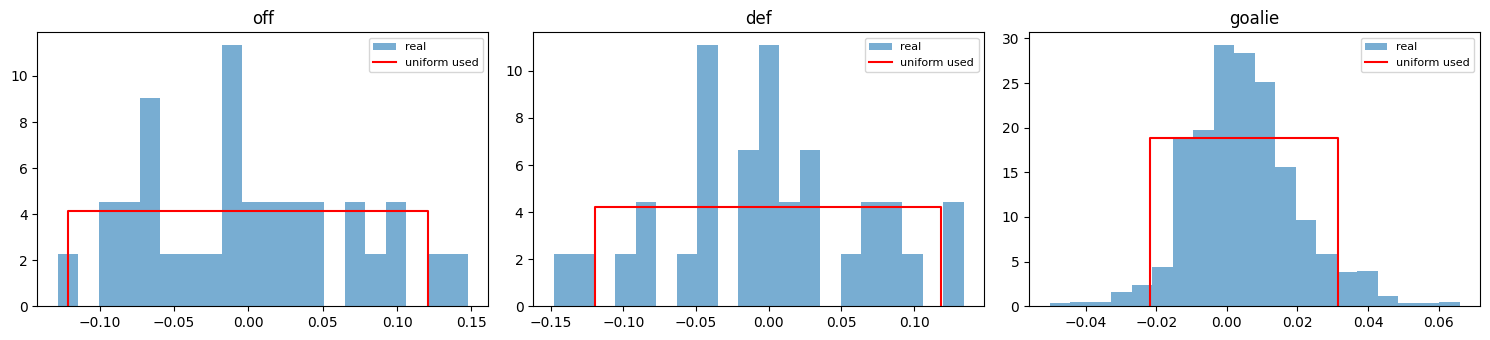

PASS   team offense varies more than goalies   (0.070 vs 0.015)


In [3]:
tab = pd.DataFrame([{"input": n, "mean": spec_info[n]["mean"], "sd": spec_info[n]["sd"],
                     "low": specs[n][1], "high": specs[n][2], "source": spec_info[n]["source"]}
                    for n in INPUT_NAMES])
print(tab.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, (vals, name) in zip(axes, [(draws["mu_off"].mean(axis=0), "off_home"),
                                   (draws["mu_def"].mean(axis=0), "def_home"),
                                   (np.r_[gt["gamma_home"], gt["gamma_away"]], "goalie_home")]):
    ax.hist(vals, bins=20, density=True, alpha=0.6, label="real")
    lo, hi = specs[name][1], specs[name][2]
    ax.plot([lo, lo, hi, hi], [0, 1 / (hi - lo), 1 / (hi - lo), 0], "r-", label="uniform used")
    ax.set_title(name.replace("_home", "")); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
check("team offense varies more than goalies", spec_info["off_home"]["sd"] > spec_info["goalie_home"]["sd"],
      f"{spec_info['off_home']['sd']:.3f} vs {spec_info['goalie_home']['sd']:.3f}")

## 4. Truth-model checks

In [4]:
# (a) game_qoi equals outcome_probs called directly
rng = np.random.default_rng(0)
Xi = pce.lhs_samples(50, len(INPUT_NAMES), seed=3)
th = pce.xi_to_theta(Xi, specs)
y = game_qoi(th, late)
direct = []
for i in range(50):
    lh = np.exp(th["alpha0"][i] + th["alpha_home"][i] + th["off_home"][i] - th["def_away"][i] - th["goalie_away"][i])
    la = np.exp(th["alpha0"][i] + th["off_away"][i] - th["def_home"][i] - th["goalie_home"][i])
    lk = {**late, "ot": {**late["ot"], "ot_factor": th["ot_factor"][i]}}
    direct.append(outcome_probs(lh, la, th["rho"][i], lk)["home_win"][0])
check("vectorized game_qoi = outcome_probs one game at a time", np.allclose(y["p_home_win"], direct, atol=1e-12))

# (b) two average teams, average goalies, posterior-mean league terms
mid = {n: np.array([spec_info[n]["mean"]]) for n in INPUT_NAMES}
m = game_qoi(mid, late)
print(f"Average vs average: P(home win) {m['p_home_win'][0]:.3f}, tied after regulation {m['p_tie_reg'][0]:.3f}, "
      f"regulation goals {m['exp_reg_goals'][0]:.2f}")
check("average matchup: home team favored a little (0.50-0.58)", 0.50 < m["p_home_win"][0] < 0.58)

# (c) direction: better home offense -> higher P(home win); better away goalie -> lower
up = {**mid, "off_home": mid["off_home"] + 0.1}
gk = {**mid, "goalie_away": mid["goalie_away"] + 0.05}
check("home offense +0.1 raises P(home win)", game_qoi(up, late)["p_home_win"][0] > m["p_home_win"][0])
check("away goalie +0.05 lowers P(home win)", game_qoi(gk, late)["p_home_win"][0] < m["p_home_win"][0])

# (d) speed
t0 = time.time(); game_qoi(pce.xi_to_theta(pce.lhs_samples(20000, 10, seed=1), specs), late)
print(f"exact model: {20000 / (time.time() - t0):,.0f} games per second")

PASS   vectorized game_qoi = outcome_probs one game at a time
Average vs average: P(home win) 0.525, tied after regulation 0.263, regulation goals 5.60
PASS   average matchup: home team favored a little (0.50-0.58)
PASS   home offense +0.1 raises P(home win)
PASS   away goalie +0.05 lowers P(home win)
exact model: 76,664 games per second


## 5. Choosing the polynomial degree

Total degree $P$ for $d = 10$ inputs: $P=2$: 66 terms, $P=3$: 286, $P=4$: 1,001, $P=5$: 3,003.
Three training points per term. The game model is smooth (logistic-like in the rating differences),
so accuracy should saturate quickly. `build_pce.py` uses $P=4$ by default. (This cell takes a few minutes: $P=5$ fits 3,003 terms.)

In [5]:
rows = []
for P in [2, 3, 4, 5]:
    nt = len(pce.total_order_indices(10, P))
    t0 = time.time()
    r = pce.build_pce_surrogate(lambda th: game_qoi(th, late), specs, P=P, N_train=3 * nt, N_test=2000,
                                seed=42, vectorized=True, verbose=False)
    for q, s in r["surrogates"].items():
        rows.append({"P": P, "terms": nt, "QoI": q, "Q2 (LOO)": s["Q2_loocv"], "hold-out R2": s["R2_holdout"],
                     "RMSE": s["RMSE_holdout"], "S_T off_home": s["S_T"][0], "seconds": time.time() - t0})
deg = pd.DataFrame(rows)
print(deg.pivot(index="P", columns="QoI", values="RMSE").to_string(float_format=lambda x: f"{x:.2e}"))
print()
print(deg.pivot(index="P", columns="QoI", values="S_T off_home").round(4).to_string())
p4 = deg[deg.P == 4]
check("P = 4: hold-out R2 > 0.9999 for every QoI", (p4["hold-out R2"] > 0.9999).all(),
      ", ".join(f"{q} {v:.6f}" for q, v in zip(p4.QoI, p4["hold-out R2"])))
check("Sobol' indices stable from P = 3 to 5 (S_T of off_home within 0.005)",
      deg.groupby("QoI").apply(lambda g: g[g.P >= 3]["S_T off_home"].std()).max() < 0.005)

QoI  exp_reg_goals  p_home_win  p_tie_reg
P                                        
2         1.49e-03    7.15e-04   2.73e-04
3         8.86e-05    6.13e-05   7.54e-05
4         1.02e-05    6.77e-06   6.70e-06
5         1.61e-06    1.02e-06   8.76e-07

QoI  exp_reg_goals  p_home_win  p_tie_reg
P                                        
2           0.2223      0.2500     0.1552
3           0.2222      0.2482     0.1540
4           0.2221      0.2482     0.1539
5           0.2221      0.2482     0.1539
PASS   P = 4: hold-out R2 > 0.9999 for every QoI   (p_home_win 1.000000, p_tie_reg 1.000000, exp_reg_goals 1.000000)
PASS   Sobol' indices stable from P = 3 to 5 (S_T of off_home within 0.005)


## 6. Surrogate accuracy (saved PCE from `build_pce.py`)

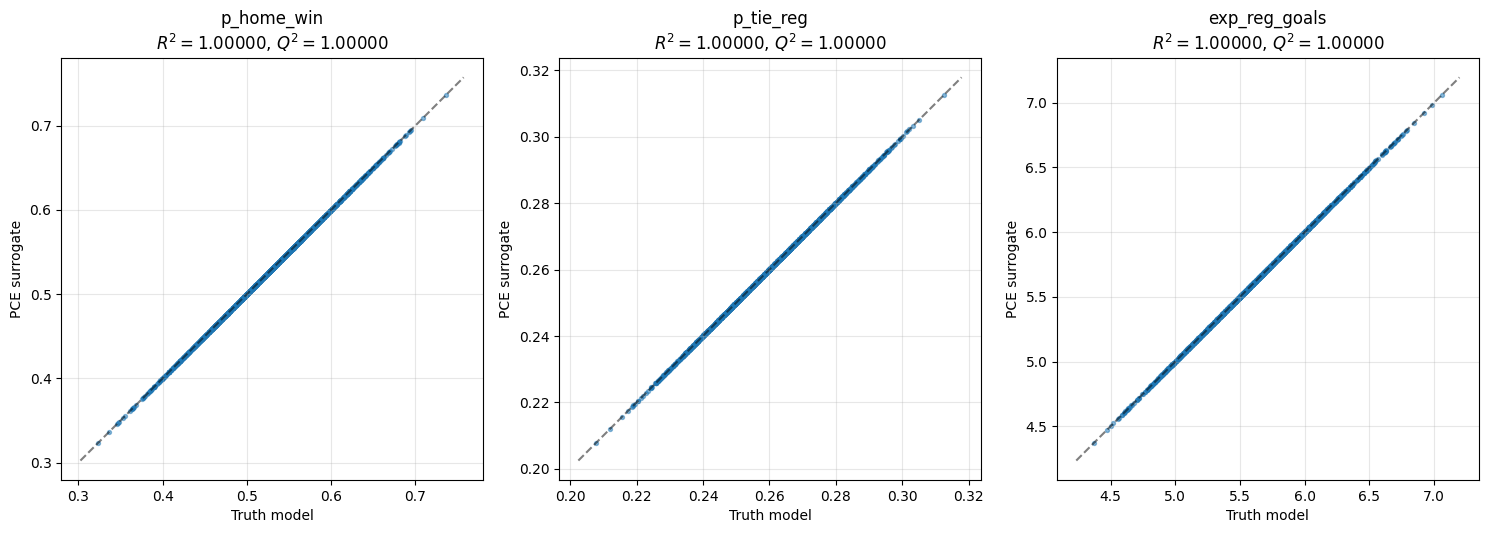

P(home win)                  Q2 1.000000   hold-out R2 1.000000   RMSE 6.77e-06   (output sd 0.0639)
P(tied after regulation)     Q2 1.000000   hold-out R2 1.000000   RMSE 6.70e-06   (output sd 0.0161)
Expected regulation goals    Q2 1.000000   hold-out R2 1.000000   RMSE 1.02e-05   (output sd 0.4364)
PASS   saved PCE errors are tiny next to the output spread (RMSE < 1% of sd)
PASS   saved PCE was built on the active fit


In [6]:
with open(STEM.with_suffix(".pkl"), "rb") as f:
    saved = pickle.load(f)
with open(f"{STEM}_summary.json") as f:
    summary = json.load(f)
mi = saved["multi_indices"]
res = {"surrogates": {q: {**s, "multi_indices": mi} for q, s in saved["surrogates"].items()},
       "Xi_test": saved["Xi_test"], "Y_test": saved["Y_test"]}
pce.plot_pce_validation(res); plt.show()
for q, s in summary["qoi"].items():
    print(f"{s['label']:28s} Q2 {s['Q2_loocv']:.6f}   hold-out R2 {s['R2_holdout']:.6f}   RMSE {s['RMSE_holdout']:.2e}"
          f"   (output sd {s['sd']:.4f})")
check("saved PCE errors are tiny next to the output spread (RMSE < 1% of sd)",
      all(s["RMSE_holdout"] < 0.01 * s["sd"] for s in summary["qoi"].values()))
check("saved PCE was built on the active fit", saved["fit_file"] == fit_path.name)

## 7. Sobol' indices, PCE vs Monte Carlo *(main result)*

PCE: analytic from the coefficients. Monte Carlo: Saltelli / Jansen on the **exact game model**
(not the surrogate), 16,384 × 12 evaluations. Agreement means the indices don't depend on the surrogate.


P(home win)  (mean 0.5244, sd 0.0639; first-order sum 0.999)
                S_i   S_T,i  S_i MC  S_T,i MC  sd alone
off_home     0.2478  0.2482  0.2478    0.2482    0.0318
def_away     0.2384  0.2388  0.2384    0.2388    0.0312
off_away     0.2339  0.2344  0.2340    0.2344    0.0309
def_home     0.2250  0.2256  0.2250    0.2256    0.0303
alpha_home   0.0306  0.0306  0.0306    0.0306    0.0112
goalie_away  0.0119  0.0120  0.0119    0.0120    0.0070
goalie_home  0.0113  0.0113  0.0112    0.0113    0.0068
alpha0       0.0000  0.0002 -0.0000    0.0002    0.0003
rho          0.0000  0.0001  0.0000    0.0001    0.0002
ot_factor    0.0000  0.0000 -0.0000    0.0000    0.0001
PASS   p_home_win: PCE and Monte Carlo agree (within 0.01)   (largest gap S 0.0001, S_T 0.0001)
PASS   p_home_win: sum of first-order indices <= 1

P(tied after regulation)  (mean 0.2594, sd 0.0161; first-order sum 0.934)
                S_i   S_T,i  S_i MC  S_T,i MC  sd alone
rho          0.5492  0.5496  0.5495    0.549

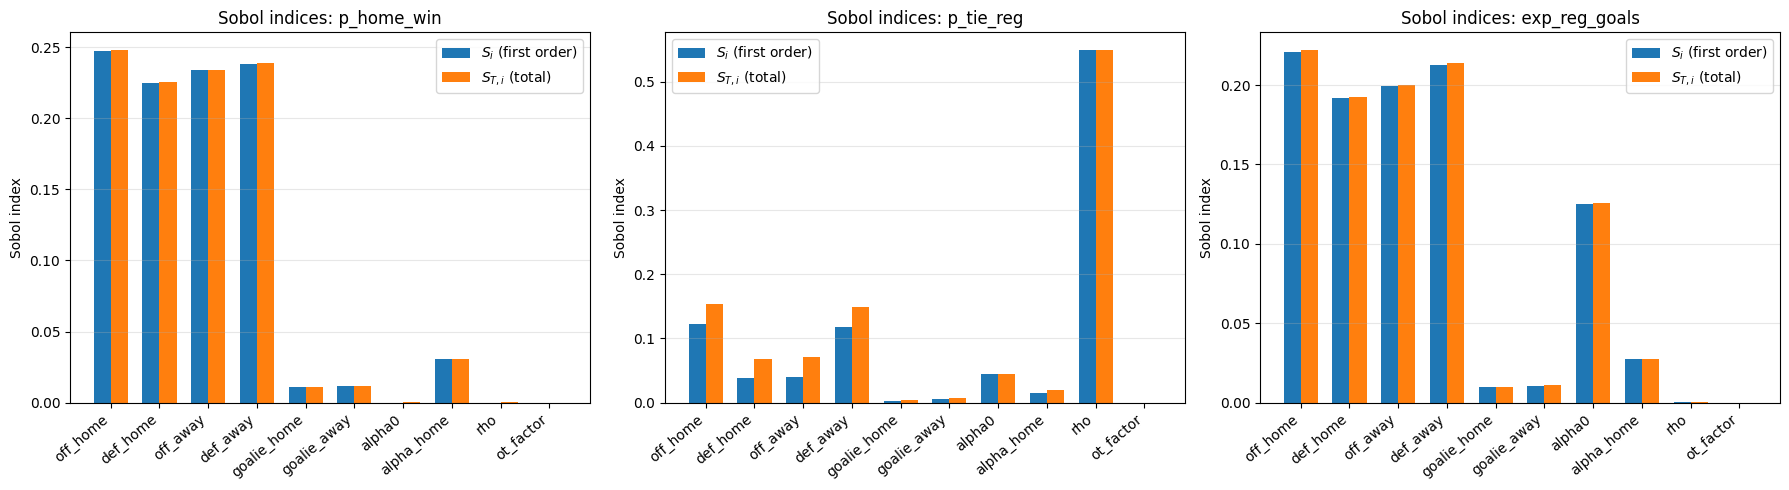

In [7]:
for q, s in summary["qoi"].items():
    sal = s.get("saltelli")
    t = pd.DataFrame({"S_i": s["S"], "S_T,i": s["S_T"],
                      **({"S_i MC": sal["S"], "S_T,i MC": sal["S_T"]} if sal else {}),
                      "sd alone": s["sd_alone"]}).loc[INPUT_NAMES]
    t = t.sort_values("S_T,i", ascending=False)
    print(f"\n{s['label']}  (mean {s['mean']:.4f}, sd {s['sd']:.4f}; first-order sum {sum(s['S'].values()):.3f})")
    print(t.round(4).to_string())
    if sal:
        diff = max(abs(s["S"][n] - sal["S"][n]) for n in INPUT_NAMES)
        diffT = max(abs(s["S_T"][n] - sal["S_T"][n]) for n in INPUT_NAMES)
        check(f"{q}: PCE and Monte Carlo agree (within 0.01)", max(diff, diffT) < 0.01,
              f"largest gap S {diff:.4f}, S_T {diffT:.4f}")
    check(f"{q}: sum of first-order indices <= 1", sum(s["S"].values()) <= 1.0001)
pce.plot_sobol(res); plt.show()

## 8. Grouped: team ratings vs goalies vs league terms

Group first-order index = variance from terms that use only that group's inputs; total = terms that use any of them.

First-order (group alone):
                  P(home win)  P(tied after regulation)  Expected regulation goals
team ratings            0.946                     0.375                      0.826
starting goalies        0.023                     0.008                      0.020
league terms            0.031                     0.608                      0.152

Total (group incl. interactions):
                  P(home win)  P(tied after regulation)  Expected regulation goals
team ratings            0.946                     0.384                      0.827
starting goalies        0.023                     0.011                      0.020
league terms            0.031                     0.614                      0.153


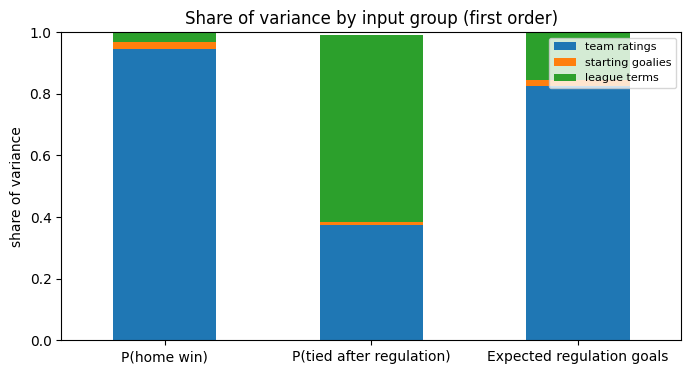

P(home win): offense 0.482, defense 0.463, goalies 0.023, home ice uncertainty 0.031


In [8]:
g = pd.DataFrame({QOI_LABELS[q]: {k: v["S"] for k, v in s["groups"].items()} for q, s in summary["qoi"].items()})
gT = pd.DataFrame({QOI_LABELS[q]: {k: v["S_T"] for k, v in s["groups"].items()} for q, s in summary["qoi"].items()})
print("First-order (group alone):"); print(g.round(3).to_string())
print("\nTotal (group incl. interactions):"); print(gT.round(3).to_string())
g.T.plot.bar(stacked=True, figsize=(8, 4), rot=0, title="Share of variance by input group (first order)")
plt.ylabel("share of variance"); plt.ylim(0, 1); plt.legend(loc="upper right", fontsize=8); plt.show()

pw = summary["qoi"]["p_home_win"]
offense = pw["S"]["off_home"] + pw["S"]["off_away"]
defense = pw["S"]["def_home"] + pw["S"]["def_away"]
print(f"P(home win): offense {offense:.3f}, defense {defense:.3f}, goalies {pw['groups']['starting goalies']['S']:.3f}, "
      f"home ice uncertainty {pw['S']['alpha_home']:.3f}")

## 9. What the indices mean in probability units

Main-effect curves: P(home win) as one input moves across its range, averaged over everything else
(computed on the PCE). Steeper and wider = more important. "sd alone" in section 7 is the spread
of each curve.

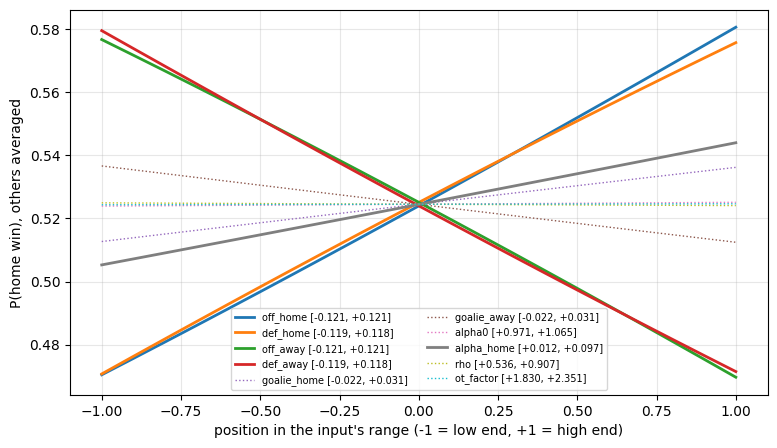

Home offense low end -> high end: P(home win) 0.471 -> 0.582
Away goalie low end -> high end:  P(home win) 0.537 -> 0.512


In [9]:
predict = pce.make_surrogate_predict(saved["surrogates"]["p_home_win"]["coefficients"], mi)
base = pce.lhs_samples(4000, len(INPUT_NAMES), seed=7)
grid = np.linspace(-1, 1, 21)
fig, ax = plt.subplots(figsize=(9, 5))
for j, n in enumerate(INPUT_NAMES):
    curve = []
    for x in grid:
        X = base.copy(); X[:, j] = x
        curve.append(predict(X).mean())
    vals = specs[n][1] + 0.5 * (grid + 1) * (specs[n][2] - specs[n][1])
    ax.plot(grid, curve, label=f"{n} [{specs[n][1]:+.3f}, {specs[n][2]:+.3f}]",
            lw=2 if pw["S_T"][n] > 0.02 else 1, ls="-" if pw["S_T"][n] > 0.02 else ":")
ax.set_xlabel("position in the input's range (-1 = low end, +1 = high end)")
ax.set_ylabel("P(home win), others averaged"); ax.grid(alpha=0.3); ax.legend(fontsize=7, ncol=2)
plt.show()

# One concrete number: best vs worst offense, average everything else
lo = {n: np.array([spec_info[n]["mean"]]) for n in INPUT_NAMES}
hi = dict(lo); hi["off_home"] = np.array([specs["off_home"][2]])
lo["off_home"] = np.array([specs["off_home"][1]])
print(f"Home offense low end -> high end: P(home win) {game_qoi(lo, late)['p_home_win'][0]:.3f} -> "
      f"{game_qoi(hi, late)['p_home_win'][0]:.3f}")
lo_g = {n: np.array([spec_info[n]["mean"]]) for n in INPUT_NAMES}; hi_g = dict(lo_g)
lo_g["goalie_away"] = np.array([specs["goalie_away"][1]]); hi_g["goalie_away"] = np.array([specs["goalie_away"][2]])
print(f"Away goalie low end -> high end:  P(home win) {game_qoi(lo_g, late)['p_home_win'][0]:.3f} -> "
      f"{game_qoi(hi_g, late)['p_home_win'][0]:.3f}")

## 10. Robustness: does the range choice change the answer?

The main modeling choice is the input ranges. Alternative: each input uniform over its **full observed range**
(teams: worst to best rating; goalies: 1st to 99th percentile of starters; league terms unchanged).
This gives extremes more weight. If the ranking of groups holds, the conclusion doesn't depend on the choice.

In [10]:
alt = dict(specs)
off_m, def_m = draws["mu_off"].mean(axis=0), draws["mu_def"].mean(axis=0)
gam = np.r_[gt["gamma_home"], gt["gamma_away"]]
for n in ["off_home", "off_away"]: alt[n] = ("linear", float(off_m.min()), float(off_m.max()))
for n in ["def_home", "def_away"]: alt[n] = ("linear", float(def_m.min()), float(def_m.max()))
for n in ["goalie_home", "goalie_away"]:
    alt[n] = ("linear", float(np.quantile(gam, 0.01)), float(np.quantile(gam, 0.99)))
nt = len(pce.total_order_indices(10, 4))
r_alt = pce.build_pce_surrogate(lambda th: game_qoi(th, late), alt, P=4, N_train=3 * nt, N_test=1000,
                                seed=42, vectorized=True, verbose=False)
rows = []
for q in summary["qoi"]:
    ga = pce.sobol_groups(r_alt["surrogates"][q]["coefficients"], r_alt["surrogates"][q]["multi_indices"],
                          GROUPS, INPUT_NAMES)
    for grp in GROUPS:
        rows.append({"QoI": QOI_LABELS[q], "group": grp, "variance-matched": summary["qoi"][q]["groups"][grp]["S"],
                     "full range": ga[grp]["S"]})
rob = pd.DataFrame(rows)
print(rob.round(3).to_string(index=False))
same_top = all(rob[rob.QoI == q].set_index("group")["variance-matched"].idxmax()
               == rob[rob.QoI == q].set_index("group")["full range"].idxmax() for q in rob.QoI.unique())
shift = (rob["full range"] - rob["variance-matched"]).abs().max()
check("largest group is the same under both range choices", same_top)
check("group shares move by less than 0.10", shift < 0.10, f"largest move {shift:.3f}")

                      QoI            group  variance-matched  full range
              P(home win)     team ratings             0.946       0.942
              P(home win) starting goalies             0.023       0.035
              P(home win)     league terms             0.031       0.023
 P(tied after regulation)     team ratings             0.375       0.458
 P(tied after regulation) starting goalies             0.008       0.014
 P(tied after regulation)     league terms             0.608       0.514
Expected regulation goals     team ratings             0.826       0.851
Expected regulation goals starting goalies             0.020       0.032
Expected regulation goals     league terms             0.152       0.116
PASS   largest group is the same under both range choices
PASS   group shares move by less than 0.10   (largest move 0.095)


## 11. Summary

In [11]:
pw, tie, tot = (summary["qoi"][q] for q in ["p_home_win", "p_tie_reg", "exp_reg_goals"])
def top(s, k=3):
    return ", ".join(f"{n} {s['S_T'][n]:.2f}" for n in sorted(INPUT_NAMES, key=lambda n: -s["S_T"][n])[:k])
print(f"P(home win):          sd {pw['sd']:.3f} across matchups; top inputs (S_T) {top(pw)}")
print(f"                      team ratings {pw['groups']['team ratings']['S']:.2f}, goalies {pw['groups']['starting goalies']['S']:.2f}, "
      f"league terms {pw['groups']['league terms']['S']:.2f}; interactions {1 - sum(pw['S'].values()):.3f}")
print(f"Tied after regulation: top inputs {top(tie)}")
print(f"Regulation goals:      top inputs {top(tot)}")

P(home win):          sd 0.064 across matchups; top inputs (S_T) off_home 0.25, def_away 0.24, off_away 0.23
                      team ratings 0.95, goalies 0.02, league terms 0.03; interactions 0.001
Tied after regulation: top inputs rho 0.55, off_home 0.15, def_away 0.15
Regulation goals:      top inputs off_home 0.22, def_away 0.21, off_away 0.20
